# Etapa 5 — "Limpar" as variáveis domésticas

Para cada variável doméstica *B* (CDS, Selic, primário):

$$B_t = a + b_1\,\Delta UST_t + b_2\,\Delta\ln VIX_t + b_3\,\Delta\ln Dólar_t + u_t$$

- A parte prevista pelas externas = **contágio global**.
- O resíduo $u_t$ = **componente genuinamente doméstico** (por construção, não correlacionado com as externas).

Depois reestimamos os modelos da etapa 4 trocando cada doméstica pelo seu resíduo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

dados = pd.read_csv("dados/tratados/variacoes_mensais.csv", index_col=0, parse_dates=True)

EXTERNAS = ["d_ust10", "dl_vix", "dl_dolar"]
DOMESTICAS = ["d_selic", "dl_cds", "d_primario"]
Y = "dl_cambio"
LAGS_HAC = 4

def mqo(y, X):
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": LAGS_HAC})

## 1. Regressões auxiliares (dados originais, não padronizados)

Aqui usamos as unidades originais para que os coeficientes tenham leitura direta.
Ex.: no CDS, ambos em 100·Δln → **elasticidade**: dólar global +1% → CDS +b₃%.

In [2]:
auxiliares = {d: mqo(dados[d], dados[EXTERNAS]) for d in DOMESTICAS}

tab_aux = pd.DataFrame({
    d: {**{v: f"{r.params[v]:.3f} (p={r.pvalues[v]:.2f})" for v in EXTERNAS}, "R²": f"{r.rsquared:.3f}"}
    for d, r in auxiliares.items()
})
tab_aux

,d_selic,dl_cds,d_primario
d_ust10,0.061 (p=0.54),-4.309 (p=0.29),0.076 (p=0.27)
dl_vix,-0.001 (p=0.27),0.128 (p=0.00),0.002 (p=0.35)
dl_dolar,0.015 (p=0.27),3.362 (p=0.00),-0.001 (p=0.92)
R²,0.008,0.350,0.016


In [3]:
# Componente doméstico = resíduo de cada regressão auxiliar
limpas = pd.DataFrame({f"{d}_dom": auxiliares[d].resid for d in DOMESTICAS})

# Conferência: correlação dos resíduos com as externas deve ser ~0 (garantido pelo MQO)
pd.concat([limpas, dados[EXTERNAS]], axis=1).corr().loc[limpas.columns, EXTERNAS].round(6)

,d_ust10,dl_vix,dl_dolar
d_selic_dom,0.0,-0.0,0.0
dl_cds_dom,0.0,-0.0,0.0
d_primario_dom,-0.0,-0.0,-0.0


## 2. Quanto do CDS foi global e quanto foi Brasil?

Somando as variações mensais (propriedade aditiva do log!), reconstruímos a trajetória do
ln(CDS) separada em parte externa e parte doméstica. Repare nos episódios:
2015 (crise fiscal/política), 2020 (Covid), fim de 2024 (estresse fiscal).

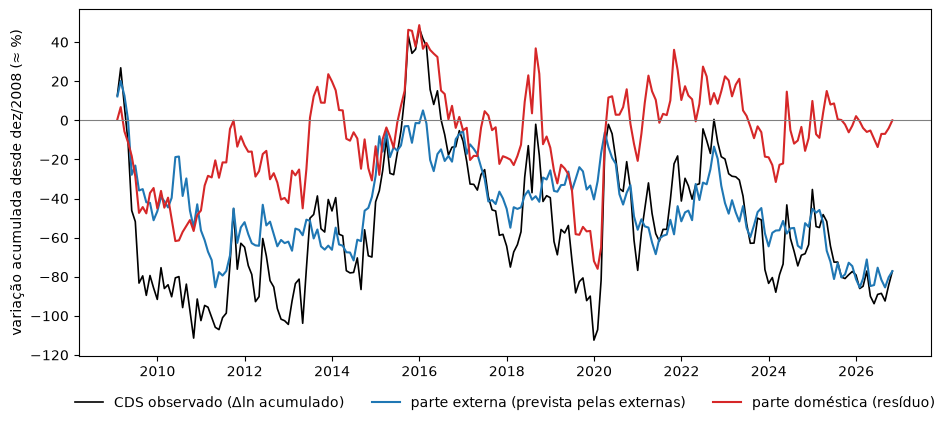

In [4]:
aux_cds = auxiliares["dl_cds"]
parte_externa = aux_cds.fittedvalues.cumsum()
parte_domestica = aux_cds.resid.cumsum()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(dados["dl_cds"].cumsum(), color="black", lw=1.2, label="CDS observado (Δln acumulado)")
ax.plot(parte_externa, color="tab:blue", label="parte externa (prevista pelas externas)")
ax.plot(parte_domestica, color="tab:red", label="parte doméstica (resíduo)")
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("variação acumulada desde dez/2008 (≈ %)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
plt.show()

## 3. Reestimação com as domésticas limpas (padronizadas)

Mesmos três modelos da etapa 4, agora com `*_dom` no lugar das domésticas originais.

In [5]:
z = (dados - dados.mean()) / dados.std()
z_limpas = limpas / limpas.std()          # resíduos já têm média zero
DOM_LIMPAS = list(limpas.columns)
zz = pd.concat([z, z_limpas], axis=1)

modelos = {
    "(1) Externas":          mqo(zz[Y], zz[EXTERNAS]),
    "(2') Domésticas limpas": mqo(zz[Y], zz[DOM_LIMPAS]),
    "(3') Completo limpo":    mqo(zz[Y], zz[EXTERNAS + DOM_LIMPAS]),
    "(3) Completo original": mqo(zz[Y], zz[EXTERNAS + DOMESTICAS]),   # da etapa 4, para comparar
}

def estrelas(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

linhas = EXTERNAS + DOM_LIMPAS + DOMESTICAS
tabela = pd.DataFrame({
    nome: {**{v: (f"{r.params[v]:.3f}{estrelas(r.pvalues[v])}" if v in r.params else "") for v in linhas},
           "R²": f"{r.rsquared:.3f}"}
    for nome, r in modelos.items()
})
tabela

,(1) Externas,(2') Domésticas limpas,(3') Completo limpo,(3) Completo original
d_ust10,-0.144**,,-0.144***,-0.097*
dl_vix,0.053,,0.053,-0.069
dl_dolar,0.588***,,0.588***,0.320***
d_selic_dom,,-0.097,-0.097**,
dl_cds_dom,,0.460***,0.460***,
d_primario_dom,,-0.025,-0.025,
d_selic,,,,-0.097**
dl_cds,,,,0.570***
d_primario,,,,-0.025
R²,0.373,0.215,0.588,0.588


## 4. Nova decomposição do R² — comparação com a etapa 4

In [6]:
def decompor(r2_ext, r2_dom, r2_tot):
    return {"só externo": r2_tot - r2_dom, "só doméstico": r2_tot - r2_ext,
            "sobreposição": r2_ext + r2_dom - r2_tot, "total": r2_tot}

r2_dom_original = mqo(zz[Y], zz[DOMESTICAS]).rsquared
antes = decompor(modelos["(1) Externas"].rsquared, r2_dom_original, modelos["(3) Completo original"].rsquared)
depois = decompor(modelos["(1) Externas"].rsquared, modelos["(2') Domésticas limpas"].rsquared,
                  modelos["(3') Completo limpo"].rsquared)

decomp = pd.DataFrame({"Etapa 4 (CDS original)": antes, "Etapa 5 (domésticas limpas)": depois}).round(3)
decomp

,Etapa 4 (CDS original),Etapa 5 (domésticas limpas)
só externo,0.068,0.373
só doméstico,0.215,0.215
sobreposição,0.305,0.000
total,0.588,0.588


In [7]:
# Participação de cada bloco no R² explicado (etapa 5)
r2_total = depois["total"]
print(f"Peso externo:   {modelos['(1) Externas'].rsquared / r2_total:.0%} do R² explicado")
print(f"Peso doméstico: {modelos["(2') Domésticas limpas"].rsquared / r2_total:.0%} do R² explicado")

Peso externo:   63% do R² explicado
Peso doméstico: 37% do R² explicado


In [8]:
# Coeficientes numéricos do modelo completo limpo (usados nos gráficos finais)
completo_limpo = modelos["(3') Completo limpo"]
coeficientes = pd.DataFrame({
    "coef": completo_limpo.params, "erro_padrao_hac": completo_limpo.bse, "p_valor": completo_limpo.pvalues,
}).drop("const")
coeficientes.to_csv("resultados/etapa5_coeficientes_limpo.csv")

limpas.to_csv("dados/tratados/domesticas_limpas.csv")
tab_aux.to_csv("resultados/etapa5_regressoes_auxiliares.csv")
tabela.to_csv("resultados/etapa5_regressoes_limpas.csv")
decomp.to_csv("resultados/etapa5_decomposicao_r2.csv")